In [1]:
import os
import neuprint as neu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

c = neu.Client('https://neuprint.janelia.org',
               dataset='male-cns:v1.0',
               token=os.environ['NEUPRINT_TOKEN'])
DATA = Path.home() / 'arm_simulation' / 'brain' / 'data'
DATA.mkdir(parents=True, exist_ok=True)
print("Connected to:", c.dataset)

Connected to: male-cns:v1.0


In [2]:
props = c.fetch_custom("""
    MATCH (n:Neuron) WITH n LIMIT 2000
    UNWIND keys(n) AS k
    RETURN k AS property, count(*) AS n ORDER BY n DESC
""")
available = set(props['property'])
print(sorted(available))

['CentralBrain', 'GNG', 'LegNp(T1)(L)', 'LegNp(T1)(R)', 'LegNp(T3)(L)', 'VNC', 'birthtime', 'bodyId', 'celltypePredictedNt', 'celltypePredictedNtConfidence', 'celltypeTotalNtPredictions', 'class', 'consensusNt', 'downstream', 'entryNerve', 'exitNerve', 'flywireType', 'fruDsx', 'group', 'instance', 'itoleeHl', 'mancBodyid', 'mancGroup', 'mancSerial', 'mancType', 'matchingNotes', 'mcnsSerial', 'post', 'pre', 'predictedNt', 'predictedNtConfidence', 'receptorType', 'roiInfo', 'rootSide', 'size', 'somaLocation', 'somaNeuromere', 'somaSide', 'status', 'statusLabel', 'subclass', 'superclass', 'supertype', 'synonyms', 'synweight', 'tosomaLocation', 'totalNtPredictions', 'trumanHl', 'type', 'upstream', 'vfbId']


In [3]:
def pick(candidates):
    return next((p for p in candidates if p in available), None)

CLASS    = pick(['superclass', 'class'])
SUBCLASS = pick(['class', 'subclass']) if CLASS == 'superclass' else pick(['subclass'])
NT       = pick(['predictedNt', 'consensusNt', 'celltypePredictedNt', 'predicted_nt'])
SIDE     = pick(['somaSide', 'rootSide', 'side'])

print(f"class={CLASS}  subclass={SUBCLASS}  nt={NT}  side={SIDE}")

class=superclass  subclass=class  nt=predictedNt  side=somaSide


In [4]:
from pathlib import Path
DATA = Path.home() / 'arm_simulation' / 'brain' / 'data'
DATA.mkdir(parents=True, exist_ok=True)

fields = {'bodyId': 'bodyId', 'type': 'type', 'instance': 'instance',
          'pre': 'pre', 'post': 'post',
          'cls': CLASS, 'subcls': SUBCLASS, 'nt': NT, 'side': SIDE}
ret = ", ".join(f"n.{p} AS {alias}" for alias, p in fields.items() if p)

neurons = c.fetch_custom(f"MATCH (n:Neuron) RETURN {ret}")
neurons.to_parquet(f'{DATA}/neurons_male-cns_v1.0.parquet')
print(len(neurons), "neurons")
neurons.head()

176422 neurons


,bodyId,type,instance,pre,post,cls,subcls,nt,side
0,45882,aPhM1,aPhM1_L,134,198,cb_sensory,mechanosensory,acetylcholine,None
1,63593,None,None,214,289,cb_sensory,mechanosensory,acetylcholine,None
2,75647,None,None,0,78,cb_intrinsic,None,None,L
3,81741,LB1c,LB1c_L,303,245,cb_sensory,gustatory,acetylcholine,None
4,98212,BM,BM_R,201,188,cb_sensory,mechanosensory,acetylcholine,None


,neurons
cls,
ol_intrinsic,89403
cb_intrinsic,32164
vnc_intrinsic,13161
None,9722
visual_projection,9201
vnc_sensory,6370
ol_sensory,6098
cb_sensory,4868
ascending_neuron,1846


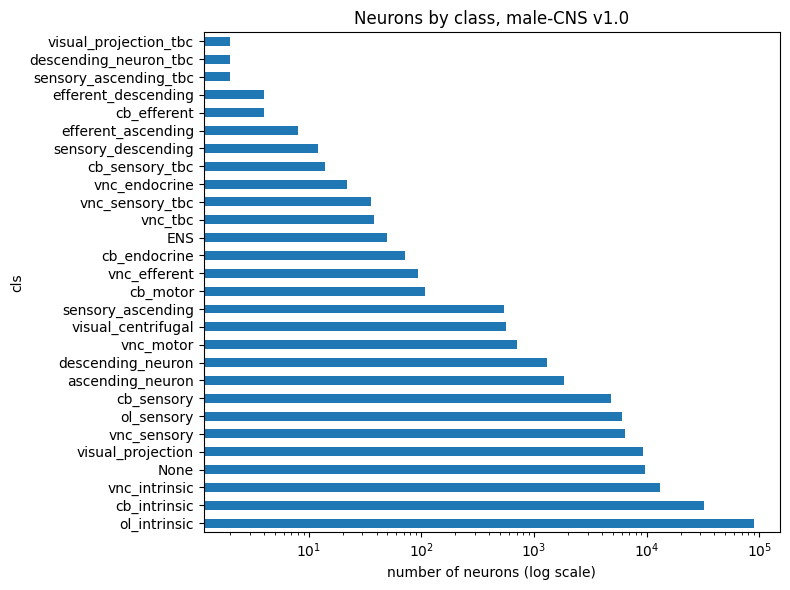

In [5]:
counts = neurons['cls'].value_counts(dropna=False)
display(counts.to_frame('neurons'))

counts.plot.barh(figsize=(8, 6), logx=True)
plt.xlabel('number of neurons (log scale)')
plt.title('Neurons by class, male-CNS v1.0')
plt.tight_layout(); plt.show()

groups = ['vnc_sensory', 'cb_sensory', 'descending_neuron', 'vnc_motor', 'cb_motor']

for g in groups:
    sub = neurons[neurons['cls'] == g]
    print(f"\n=== {g}: {len(sub)} neurons ===")
    display(sub['subcls'].value_counts(dropna=False).head(15).to_frame('neurons'))

,neurons
nt,
acetylcholine,95409
glutamate,28199
unclear,22902
gaba,20357
dopamine,4447
None,2257
histamine,2242
serotonin,483
octopamine,126


nt,acetylcholine,dopamine,gaba,glutamate,histamine,octopamine,serotonin,unclear
cls,,,,,,,,
ENS,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
ascending_neuron,0.69,0.00,0.21,0.07,0.00,0.00,0.01,0.01
cb_efferent,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
cb_endocrine,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0.97
cb_intrinsic,0.46,0.14,0.15,0.21,0.00,0.00,0.01,0.03
cb_motor,0.17,0.00,0.00,0.03,0.00,0.00,0.01,0.79
cb_sensory,0.75,0.00,0.00,0.00,0.00,0.00,0.01,0.24
cb_sensory_tbc,0.45,0.00,0.09,0.09,0.00,0.09,0.00,0.27
descending_neuron,0.71,0.00,0.18,0.08,0.00,0.01,0.01,0.01


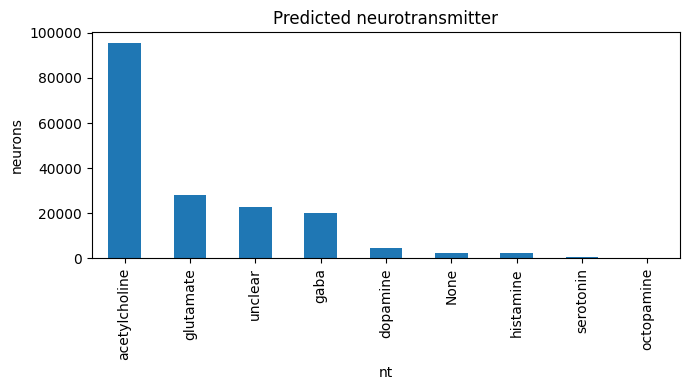

In [6]:
nt_counts = neurons['nt'].value_counts(dropna=False)
display(nt_counts.to_frame('neurons'))

# Neurotransmitter mix within each class, as fractions
mix = pd.crosstab(neurons['cls'], neurons['nt'], normalize='index').round(2)
display(mix)

nt_counts.plot.bar(figsize=(7, 4))
plt.ylabel('neurons'); plt.title('Predicted neurotransmitter')
plt.tight_layout(); plt.show()

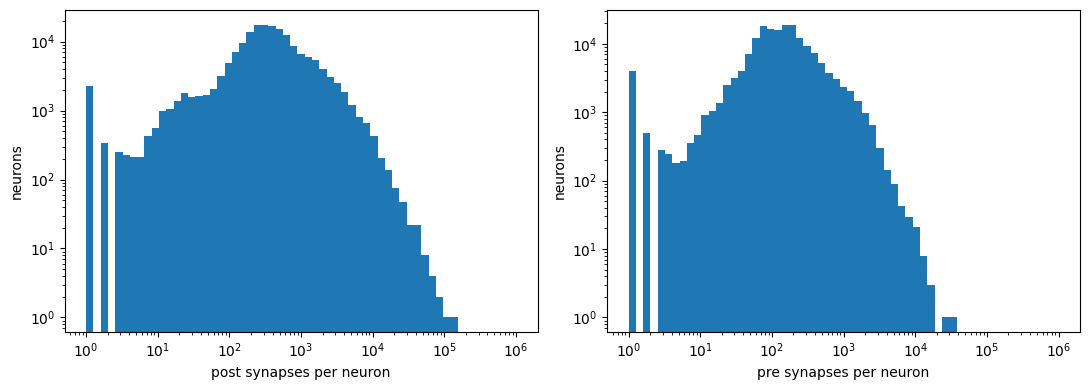

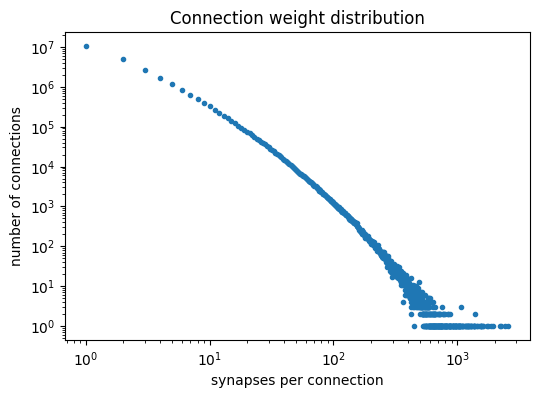

Total connections: 25862574
Connections with ≥5 synapses: 6287789


In [7]:
# Per-neuron totals of input (post) and output (pre) synapses
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col in zip(ax, ['post', 'pre']):
    a.hist(neurons[col].clip(lower=1), bins=np.logspace(0, 6, 60))
    a.set_xscale('log'); a.set_yscale('log')
    a.set_xlabel(f'{col} synapses per neuron'); a.set_ylabel('neurons')
plt.tight_layout(); plt.show()

# Per-connection weights, counted on the server so the whole edge table isn't downloaded
w = c.fetch_custom("""
    MATCH (:Neuron)-[e:ConnectsTo]->(:Neuron)
    RETURN e.weight AS weight, count(*) AS n_connections
    ORDER BY weight
""")
w.to_parquet(f'{DATA}/weight_histogram.parquet')

plt.figure(figsize=(6, 4))
plt.loglog(w['weight'], w['n_connections'], '.')
plt.xlabel('synapses per connection'); plt.ylabel('number of connections')
plt.title('Connection weight distribution'); plt.show()

print("Total connections:", w['n_connections'].sum())
print("Connections with ≥5 synapses:", w.loc[w.weight >= 5, 'n_connections'].sum())